# 04 — Bayesian hyperparameter optimisation (XGBoost)

XGBoost was selected for tuning from the model comparison (`03_model_comparison.ipynb`): best student-test
Top-1 and log loss, a small train-vs-CV gap, and ~12 s per fit, which keeps a Bayesian search affordable.

**Method** (`pathsnap/hpo/xgb_optuna.py`)
- Optuna with the **TPE sampler** (Bayesian: models good and bad regions of the space from past trials, samples
  where improvement is likely), seed 42, 10 random start-up trials.
- **Objective**: mean observation-level Top-1 accuracy over the same 5-fold `GroupKFold` on the 80 train trips
  (grouped by `trip_id`). Macro F1 and log loss are recorded per trial.
- **Median pruner**: stops a trial whose running fold mean falls below the median of earlier trials.
- Trial 0 is the untuned configuration.
- Student-test data is used only after the search, to compare tuned vs untuned; evaluator data is never used.
- The study is saved in `results/hpo/xgb_study.db` (full search record, resumable).

In [1]:
# --- setup: find the repo, check the saved study ---
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import optuna
from IPython.display import Image, display
from pathsnap.config import RESULTS_DIR
from pathsnap.hpo.xgb_optuna import load_study, BASELINE
from pathsnap.viz import hpo_plots

H = RESULTS_DIR / "hpo"
if not (H / "xgb_study.db").exists():
    raise RuntimeError("No study found. Run: python -m pathsnap.hpo.xgb_optuna --trials 50 "
                       "and then python -m pathsnap.hpo.xgb_optuna --refit")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
study = load_study()
optuna.logging.set_verbosity(optuna.logging.WARNING)

/run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[I 2026-11-18 12:14:00,527] Using an existing study with `study_name='xgb_top1'` instead of creating a new one.


## 1. Search space

In [2]:
space = pd.DataFrame([
    ("n_estimators", "int 100-1000, step 50", "boosting rounds; more rounds fit more but can overfit"),
    ("learning_rate", "float 0.01-0.3, log", "shrinkage per round; trades off against n_estimators"),
    ("max_depth", "int 3-10", "interaction depth of each tree"),
    ("min_child_weight", "float 1-50, log", "minimum hessian per leaf; larger = smoother model"),
    ("subsample", "float 0.5-1.0", "row sampling per tree (regularisation)"),
    ("colsample_bytree", "float 0.5-1.0", "feature sampling per tree"),
    ("gamma", "float 0-5", "minimum loss reduction to make a split"),
    ("reg_lambda", "float 0.001-10, log", "L2 penalty on leaf weights"),
    ("reg_alpha", "float 0.001-10, log", "L1 penalty on leaf weights"),
], columns=["hyperparameter", "range / distribution", "role"])
space["untuned value"] = space["hyperparameter"].map(BASELINE)
space

,hyperparameter,range / distribution,role,untuned value
0,n_estimators,"int 100-1000, step 50",boosting rounds; more rounds fit more but can ...,400.000
1,learning_rate,"float 0.01-0.3, log",shrinkage per round; trades off against n_esti...,0.050
2,max_depth,int 3-10,interaction depth of each tree,6.000
3,min_child_weight,"float 1-50, log",minimum hessian per leaf; larger = smoother model,1.000
4,subsample,float 0.5-1.0,row sampling per tree (regularisation),1.000
5,colsample_bytree,float 0.5-1.0,feature sampling per tree,1.000
6,gamma,float 0-5,minimum loss reduction to make a split,0.000
7,reg_lambda,"float 0.001-10, log",L2 penalty on leaf weights,1.000
8,reg_alpha,"float 0.001-10, log",L1 penalty on leaf weights,0.001


## 2. Search record

In [3]:
trials = pd.read_csv(H / "xgb_trials.csv")
states = trials["state"].value_counts()
print("trials:", states.to_dict(), "| total search time:", round(trials["duration_s"].sum() / 60, 1), "min")
cols = ["number", "value", "state", "user_attrs_cv_macro_f1", "user_attrs_cv_log_loss", "duration_s"] + \
       [c for c in trials.columns if c.startswith("params_")]
trials[cols].sort_values("value", ascending=False).head(10).round(4)

trials: {'COMPLETE': 25, 'PRUNED': 25} | total search time: 44.0 min


,number,value,state,user_attrs_cv_macro_f1,user_attrs_cv_log_loss,duration_s,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample
45,45,0.8604,PRUNED,NaN,NaN,41.5841,0.5284,1.0065,0.0127,9,34.3569,950,0.5631,0.0479,0.5835
42,42,0.8604,PRUNED,NaN,NaN,30.6145,0.5265,0.1974,0.0237,10,33.9623,650,0.3115,0.0279,0.5723
44,44,0.8602,PRUNED,NaN,NaN,37.3580,0.6242,0.9509,0.0200,9,31.1163,800,0.7722,0.0037,0.6506
18,18,0.8601,PRUNED,NaN,NaN,16.6540,0.5799,4.1427,0.0564,8,45.1452,450,0.0215,0.1410,0.9204
34,34,0.8601,PRUNED,NaN,NaN,24.6100,0.5692,4.6799,0.0142,9,33.5426,450,0.0025,0.0347,0.8145
13,13,0.8599,PRUNED,NaN,NaN,28.4589,0.6238,3.6946,0.0271,9,10.8807,600,0.0033,0.0362,0.9402
33,33,0.8599,PRUNED,NaN,NaN,18.6906,0.5904,4.9710,0.0208,8,3.1991,350,0.0101,0.4347,0.9245
24,24,0.8599,PRUNED,NaN,NaN,12.0242,0.5511,3.4100,0.0383,9,33.2028,150,0.0064,0.0825,0.8455
39,39,0.8599,PRUNED,NaN,NaN,17.3681,0.5469,4.8179,0.0388,8,20.7469,600,0.0160,1.1040,0.8118
16,16,0.8599,PRUNED,NaN,NaN,23.4361,0.5691,3.9862,0.0200,7,16.8231,450,0.0130,0.0252,0.7473


## 3. Best configuration

In [4]:
best = pd.DataFrame({"untuned": pd.Series(BASELINE), "best": pd.Series(study.best_params)})
print(f"best trial #{study.best_trial.number}: CV top-1 {study.best_value:.4f} "
      f"(untuned trial 0: {study.trials[0].value:.4f})")
best

best trial #12: CV top-1 0.8515 (untuned trial 0: 0.8492)


,untuned,best
n_estimators,400.000,400.000000
learning_rate,0.050,0.026888
max_depth,6.000,8.000000
min_child_weight,1.000,30.544761
subsample,1.000,0.834885
colsample_bytree,1.000,0.529625
gamma,0.000,3.667348
reg_lambda,1.000,0.049295
reg_alpha,0.001,0.004034


## 4. Plots

plots -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/hpo/plots


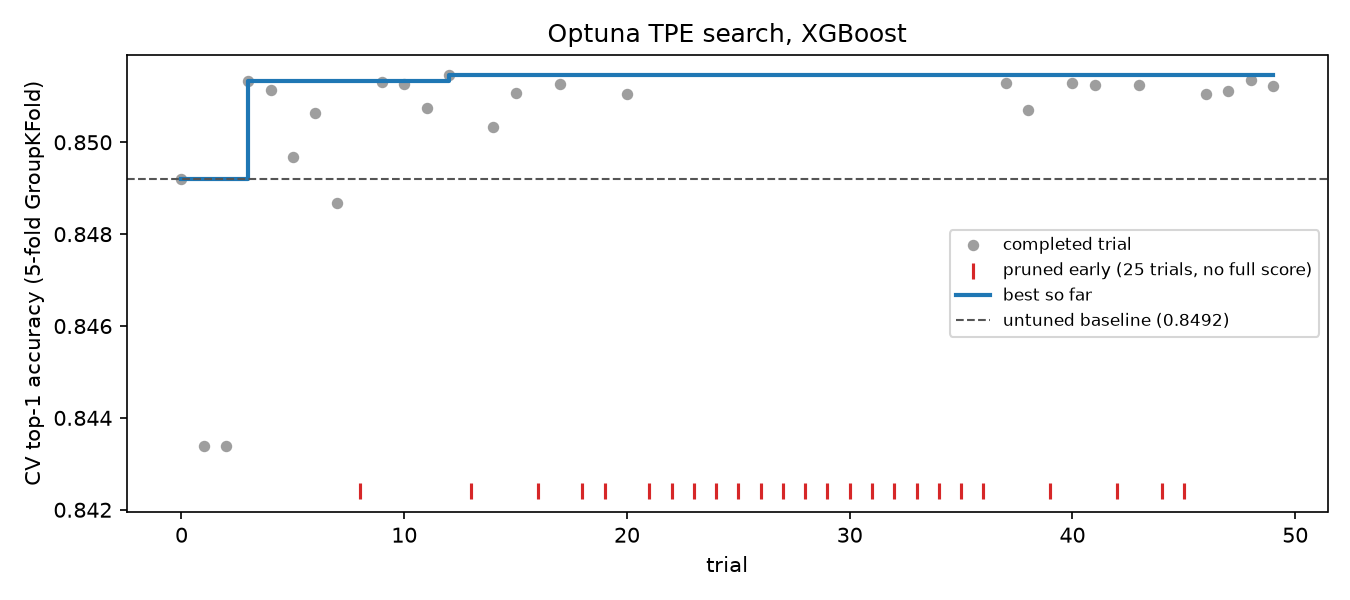

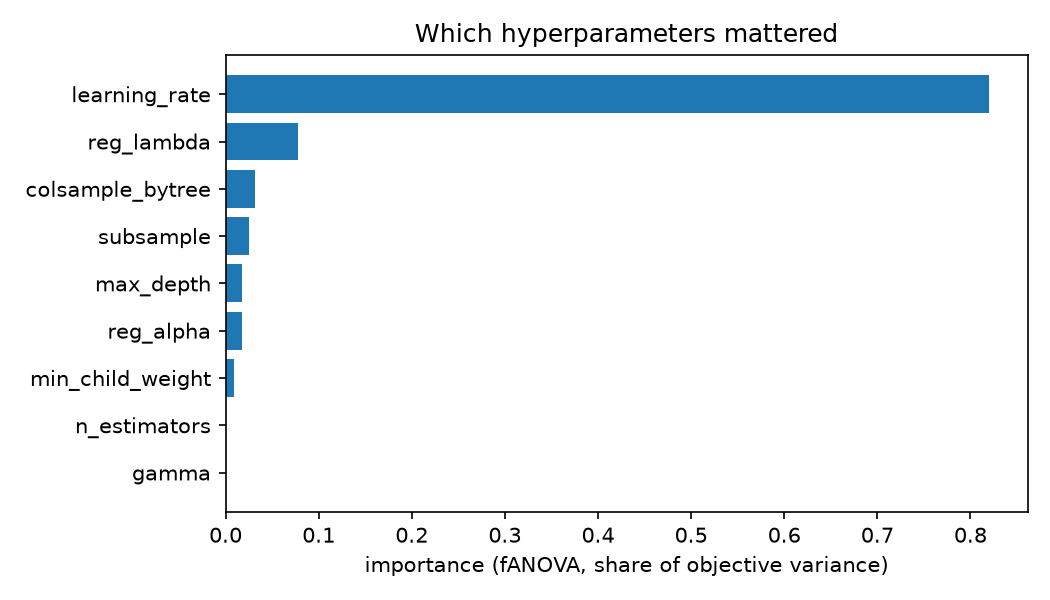

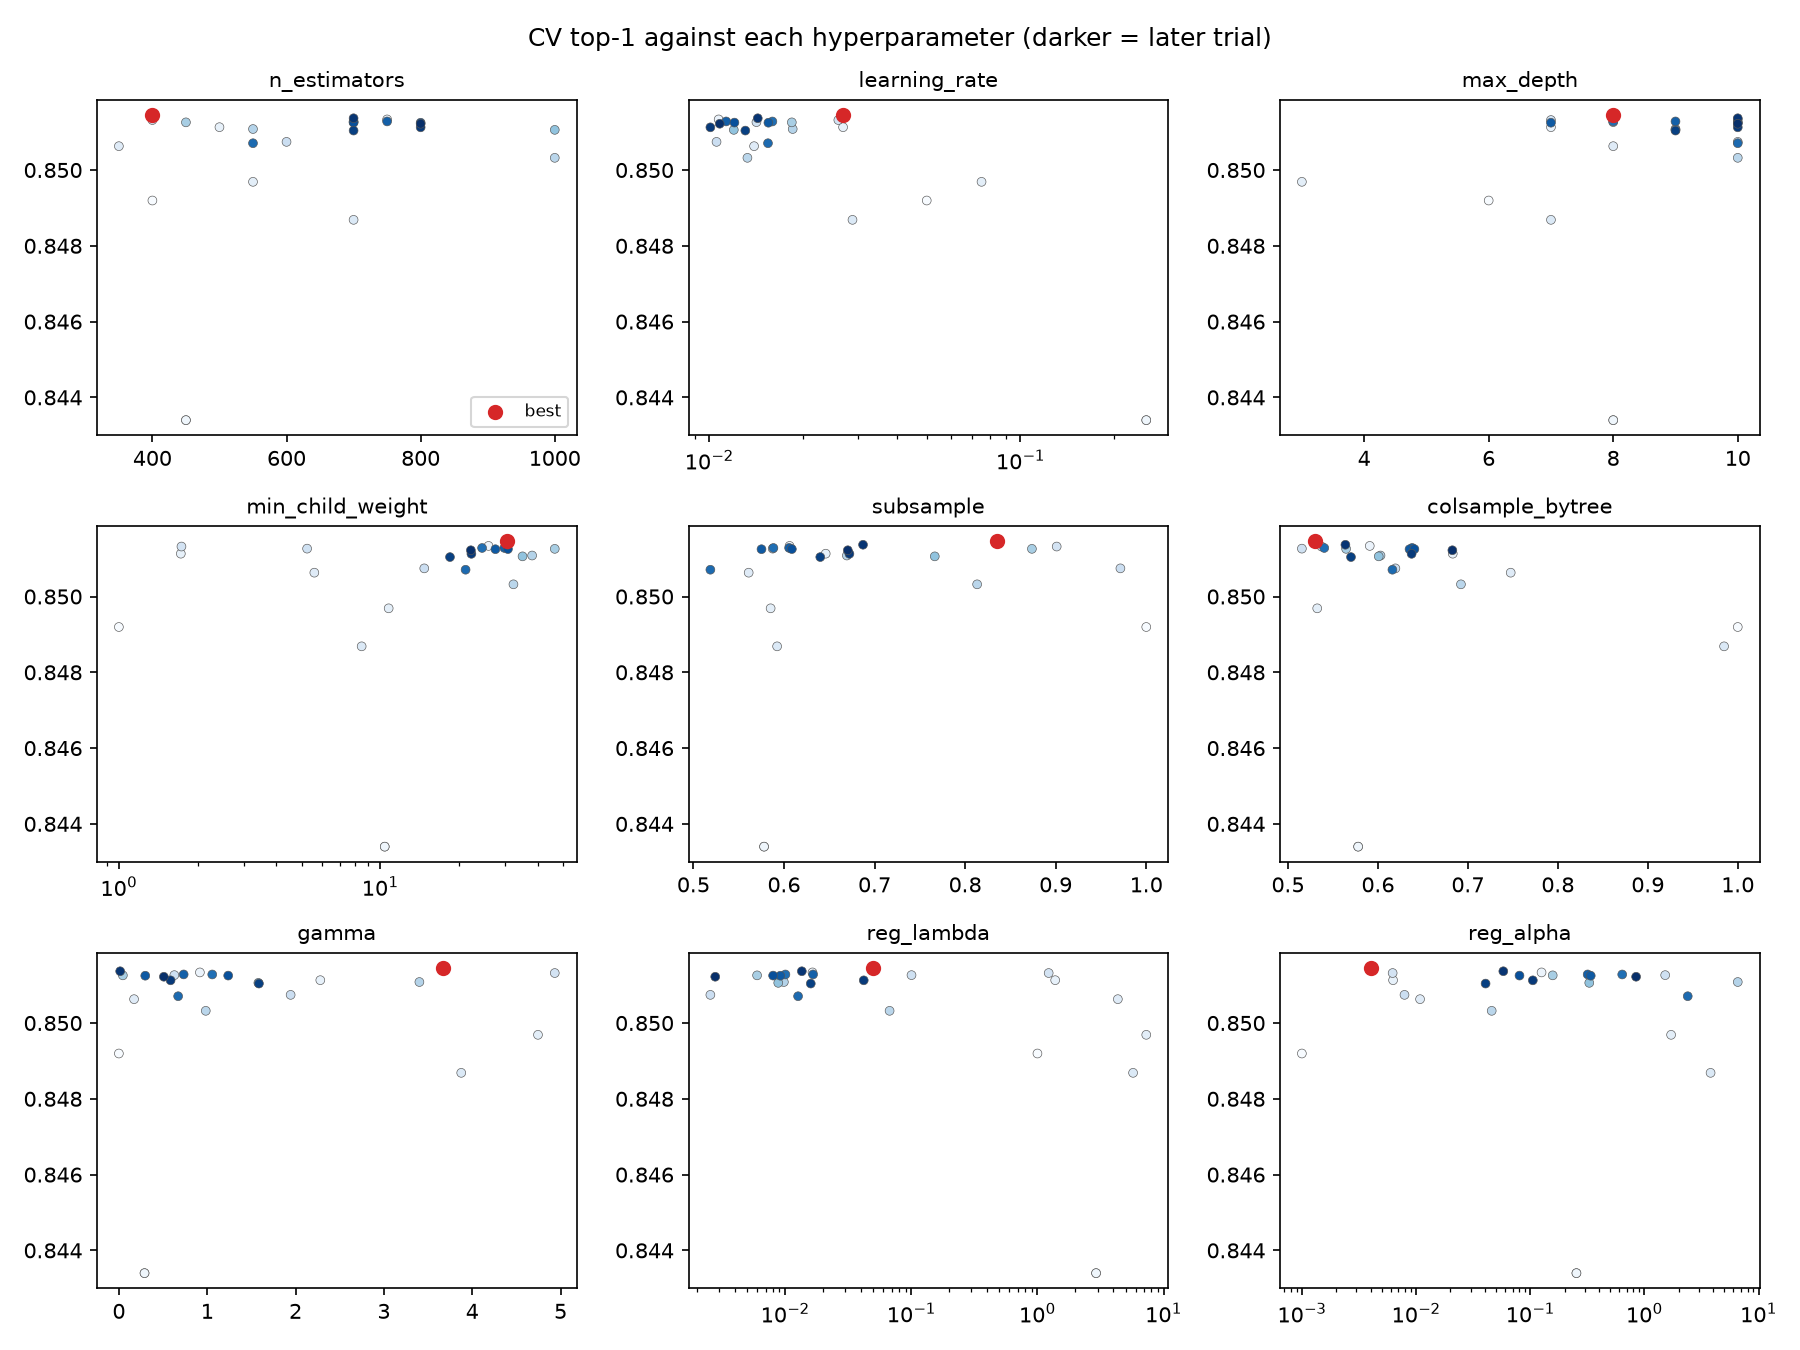

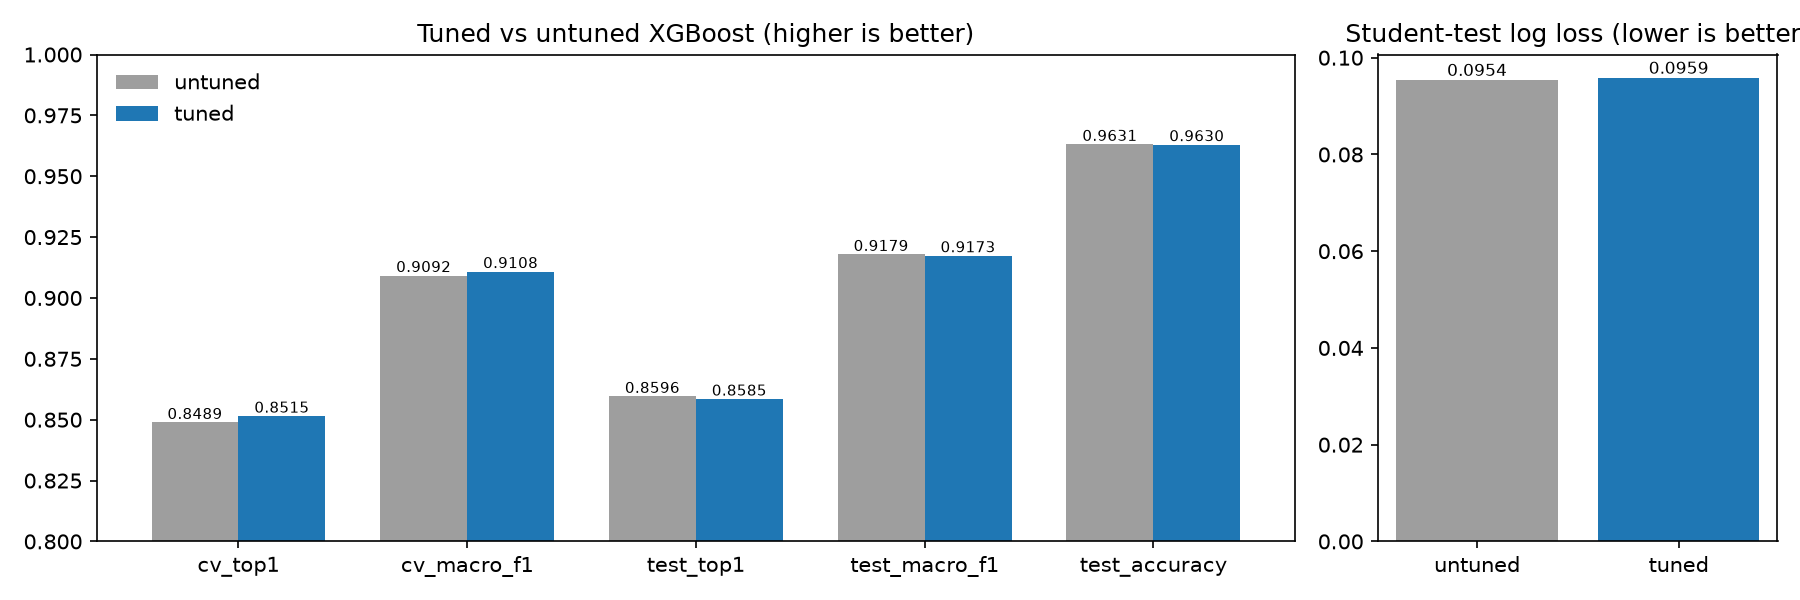

In [5]:
hpo_plots.main()
for f in ["optimisation_history.png", "param_importance.png", "param_slices.png", "tuned_vs_untuned.png"]:
    display(Image(filename=str(H / "plots" / f)))

## 5. Tuned vs untuned (same folds, same student-test trips)

The tuned model is refitted through the same harness as every other model (`python -m pathsnap.hpo.xgb_optuna --refit`).

In [6]:
cmp = pd.read_csv(H / "xgb_tuned_vs_untuned.csv").set_index("model")
diff = (cmp.loc["tuned"] - cmp.loc["untuned"]).rename("tuned - untuned")
pd.concat([cmp.T, diff], axis=1).round(4)

,untuned,tuned,tuned - untuned
cv_macro_f1,0.9092,0.9108,0.0016
cv_top1,0.8489,0.8515,0.0026
cv_log_loss,0.1140,0.1111,-0.0029
test_top1,0.8596,0.8585,-0.0011
test_accuracy,0.9631,0.9630,-0.0001
test_macro_f1,0.9179,0.9173,-0.0005
test_log_loss,0.0954,0.0959,0.0004
test_route_continuity,0.9458,0.9462,0.0004
fit_seconds,12.1196,11.7950,-0.3245
inference_ms_per_1000_points,8.4378,12.0794,3.6416


## 6. Why tuning adds so little: where the remaining errors are

Every model scored 84-86% Top-1, so the ceiling comes from the data, not from XGBoost settings.
Each student-test point is classified by how the predicted arc relates to the reference arc
(`python -m pathsnap.models.error_analysis`).

In [7]:
from pathsnap.models.error_analysis import breakdown
from pathsnap.config import ARTIFACTS_DIR
eb = breakdown(ARTIFACTS_DIR / "final_model.joblib", "final_model")


[final_model] 19133 student_test points -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/models/error_breakdown_final_model.csv
                          points  share_pct  gps_heading_agrees_with_prediction_pct
category                                                                           
correct                    16425      85.85                                     NaN
reverse twin                1353       7.07                                   83.07
next/previous arc            401       2.10                                     NaN
sibling at same junction     488       2.55                                     NaN
other road                   452       2.36                                     NaN
label not a candidate         14       0.07                                     NaN


- **reverse twin**: same street, opposite direction. In most of these the GPS travel direction agrees with the
  *prediction*, not with the reference arc, so they point to direction noise in the reference route rather than
  model errors.
- **next/previous arc** and **sibling at same junction**: the point lies at a junction where two arcs meet;
  either answer is geometrically defensible.
- **other road**: genuinely wrong roads.
- **label not a candidate**: unrecoverable by any classifier (candidate miss rate).

Sequence information (HMM/Viterbi, next stage) targets the junction and other-road errors by enforcing
connected routes.

## 7. Computational cost

Total search time is the sum of trial durations above (5 fits per completed trial, fewer for pruned ones,
16 CPU threads). The final refit is a single fit on all train trips. The tuned model is saved as
`artifacts/final_model.joblib` with its parameters in `artifacts/final_model.json`, for the HMM decoder and the API.